# Исследование датасета стоимости недвижимости в Турции

# 1. Исследование данных (EDA)

На этом этапе модель ещё не обучается. Задача — понять, что находится в датасете, какие признаки доступны и какие проблемы качества данных нужно учитывать.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    median_absolute_error
)
from lightgbm import LGBMRegressor

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
FILE_NAME = "real_estate_data_ru_FINAL2.csv"

df = pd.read_csv(FILE_NAME, sep=";", low_memory=False)

print("Файл:", FILE_NAME)
print("Размер исходного набора:", df.shape)
print("Количество строк:", len(df))
print("Количество столбцов:", len(df.columns))

Файл: real_estate_data_ru_FINAL2.csv
Размер исходного набора: (403487, 17)
Количество строк: 403487
Количество столбцов: 17


## 1.1 Первичный просмотр

In [2]:
display(df.head())
display(df.sample(5, random_state=RANDOM_STATE))
df.info()

,идентификатор,тип_недвижимости,подтип,дата_начала,дата_окончания,тип_объявления,дней_на_рынке,возраст_здания,всего_этажей,этаж,комнаты,площадь_м2,адрес,мебель,тип_отопления,цена,валюта
0,1,Жилая недвижимость,Резиденция,12.10.2018,01.09.2019,Аренда,30,Новое здание,20 и более,2,2+1,90.0,Стамбул/Картал/Кордонбойу,NaN,Фанкойл,3500.0,Турецкая лира
1,2,Жилая недвижимость,Квартира,2/13/19,NaN,Продажа,14,Новое здание,20 и более,20 ve üzeri,1+0,43.0,Стамбул/Картал/Кордонбойу,NaN,Фанкойл,490000.0,Турецкая лира
2,3,Жилая недвижимость,Квартира,10.09.2018,11.08.2018,Продажа,30,Новое здание,1,Yüksek Giriş,2+1,NaN,Текирдаг/Чорлу/Решадийе,NaN,Фанкойл,155000.0,Турецкая лира
3,4,Жилая недвижимость,Резиденция,09.10.2018,10.10.2018,Продажа,30,3,20 и более,20 ve üzeri,6+1,450.0,Стамбул/Бешикташ/Левент,NaN,Фанкойл,32500000.0,Турецкая лира
4,5,Жилая недвижимость,Резиденция,12.10.2018,01.09.2019,Продажа,30,Новое здание,20 и более,2,2+1,90.0,Стамбул/Картал/Кордонбойу,NaN,Фанкойл,1450000.0,Турецкая лира


,идентификатор,тип_недвижимости,подтип,дата_начала,дата_окончания,тип_объявления,дней_на_рынке,возраст_здания,всего_этажей,этаж,комнаты,площадь_м2,адрес,мебель,тип_отопления,цена,валюта
60623,60624,Жилая недвижимость,Квартира,11/20/18,2/23/19,Продажа,95,6-10,5,1,2+1,120.0,Анталья/Аланйа/Оба,NaN,Кондиционер,240000.0,Турецкая лира
401384,401385,Жилая недвижимость,Отдельный дом,11/27/18,02.01.2019,Продажа,66,NaN,NaN,NaN,5+1,350.0,Мугла/Бодрум/Гюндоган,NaN,NaN,3850000.0,Турецкая лира
207138,207139,Жилая недвижимость,Квартира,12.08.2018,02.04.2019,Продажа,58,Новое здание,5,3,2+1,80.0,Маниса/Йунусемре/Мурадийе,NaN,Газовый котёл,120000.0,Турецкая лира
51585,51586,Жилая недвижимость,Квартира,01.11.2019,NaN,Продажа,47,Новое здание,5,Kot 1,1+1,45.0,Стамбул/Кагытхане/Емнийет Евлери,NaN,Кондиционер,185000.0,Турецкая лира
168182,168183,Жилая недвижимость,Квартира,11/24/18,NaN,Продажа,95,Новое здание,4,1,3+2,130.0,Стамбул/Санджактепе/Йенидоган,NaN,Газовый котёл,418000.0,Турецкая лира


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 403487 entries, 0 to 403486
Data columns (total 17 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   идентификатор     403487 non-null  int64  
 1   тип_недвижимости  403487 non-null  object 
 2   подтип            403487 non-null  object 
 3   дата_начала       403487 non-null  object 
 4   дата_окончания    266298 non-null  object 
 5   тип_объявления    403487 non-null  object 
 6   дней_на_рынке     403487 non-null  int64  
 7   возраст_здания    376097 non-null  object 
 8   всего_этажей      375466 non-null  object 
 9   этаж              368191 non-null  object 
 10  комнаты           403487 non-null  object 
 11  площадь_м2        257481 non-null  float64
 12  адрес             403487 non-null  object 
 13  мебель            0 non-null       float64
 14  тип_отопления     375517 non-null  object 
 15  цена              402772 non-null  float64
 16  валюта            40

## 1.2 Основные категории и валюты

In [3]:
print("Тип объявления:")
display(df["тип_объявления"].value_counts(dropna=False))

print("Тип недвижимости:")
display(df["тип_недвижимости"].value_counts(dropna=False).head(10))

print("Валюта:")
display(df["валюта"].value_counts(dropna=False))

Тип объявления:


тип_объявления
Продажа    287009
Аренда     114236
3            2242
Name: count, dtype: int64

Тип недвижимости:


тип_недвижимости
Жилая недвижимость    403487
Name: count, dtype: int64

Валюта:


валюта
Турецкая лира      400677
Евро                  922
NaN                   715
Фунт стерлингов       621
Доллар США            552
Name: count, dtype: int64

Отдельно проверили валюту, потому что цену в евро, долларах, фунтах и лирах нельзя напрямую сравнивать как одно числовое значение. Поэтому на этапе формирования модельной выборки оставляем единую валюту — турецкую лиру».

## 1.3 Числовые признаки

In [4]:
numeric_cols_eda = ["цена", "площадь_м2", "дней_на_рынке"]
display(df[numeric_cols_eda].describe().T)

,count,mean,std,min,25%,50%,75%,max
цена,402772.0,354641.661933,4.809503e+06,-250.0,2500.0,199000.0,342000.0,2.000000e+09
площадь_м2,257481.0,279.349094,9.429195e+03,1.0,85.0,110.0,140.0,9.482350e+05
дней_на_рынке,403487.0,57.022739,4.435893e+01,0.0,29.0,40.0,90.0,1.800000e+02


Смотрим минимум, максимум, среднее и медиану. Особенно важна разница между средним и медианой: она позволяет заметить сильную асимметрию и возможные выбросы

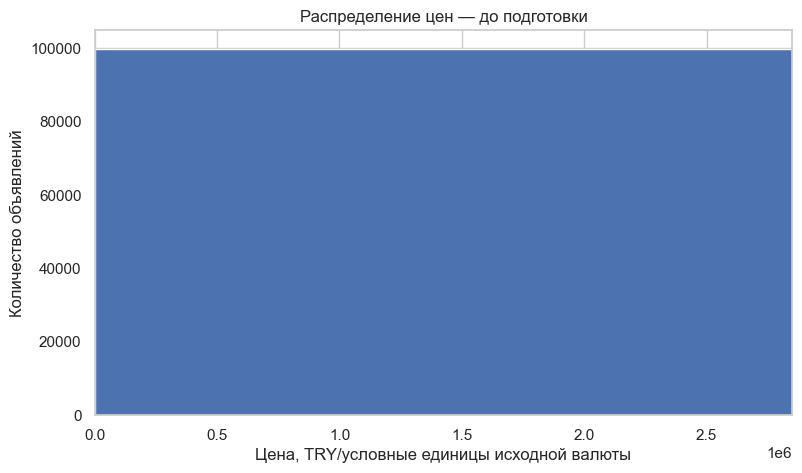

In [5]:
price_all = pd.to_numeric(df["цена"], errors="coerce").dropna()

plt.figure(figsize=(9, 5))
plt.hist(price_all.sample(min(100000, len(price_all)), random_state=RANDOM_STATE), bins=80)
plt.xlim(0, price_all.quantile(0.99))
plt.title("Распределение цен — до подготовки")
plt.xlabel("Цена, TRY/условные единицы исходной валюты")
plt.ylabel("Количество объявлений")
plt.show()

На графике видно, что распределение цен сильно скошено вправо: основная масса объектов находится в относительно меньшем диапазоне, а небольшая часть объектов имеет очень большие значения. Поэтому дальше я отдельно рассматриваю логарифмирование целевой переменной

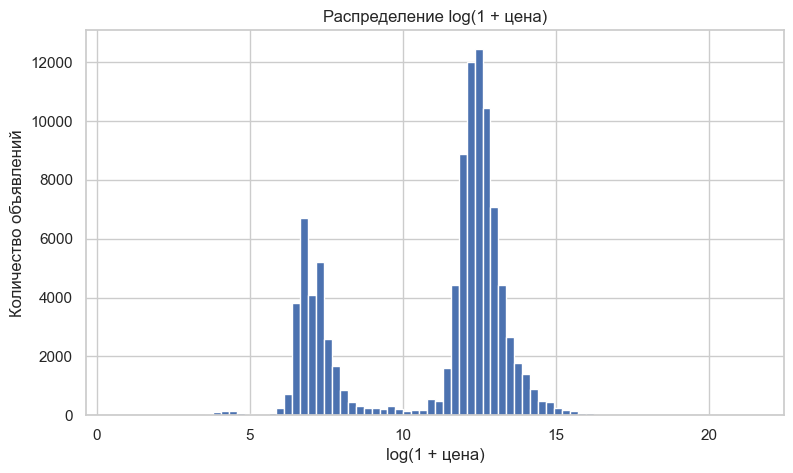

In [6]:
positive_price = price_all[price_all > 0]
log_price = np.log1p(positive_price)

plt.figure(figsize=(9, 5))
plt.hist(log_price.sample(min(100000, len(log_price)), random_state=RANDOM_STATE), bins=80)
plt.title("Распределение log(1 + цена)")
plt.xlabel("log(1 + цена)")
plt.ylabel("Количество объявлений")
plt.show()

Логарифмирование не меняет порядок объектов, но сжимает большие значения. Это уменьшает влияние экстремально дорогих объектов при обучении и делает распределение более удобным для регрессии. После прогнозирования я выполняю обратное преобразование `expm1`

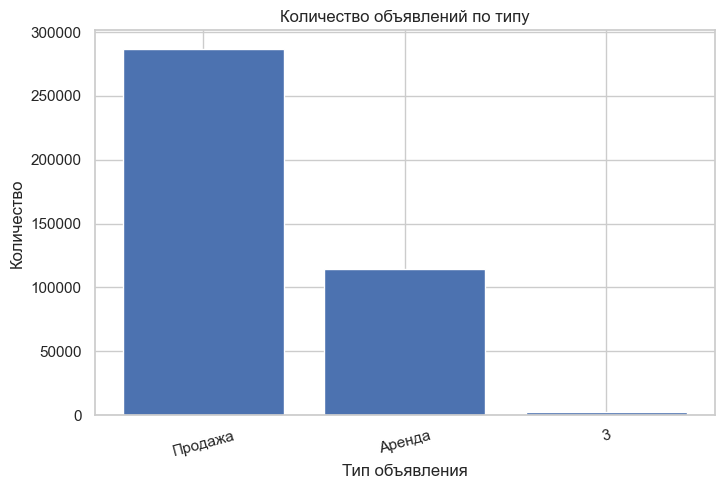

In [7]:
type_counts = df["тип_объявления"].value_counts(dropna=False)
plt.figure(figsize=(8, 5))
plt.bar(type_counts.index.astype(str), type_counts.values)
plt.title("Количество объявлений по типу")
plt.xlabel("Тип объявления")
plt.ylabel("Количество")
plt.xticks(rotation=15)
plt.show()

На исходном этапе обнаружено некорректное значение `3` в признаке `тип_объявления`.

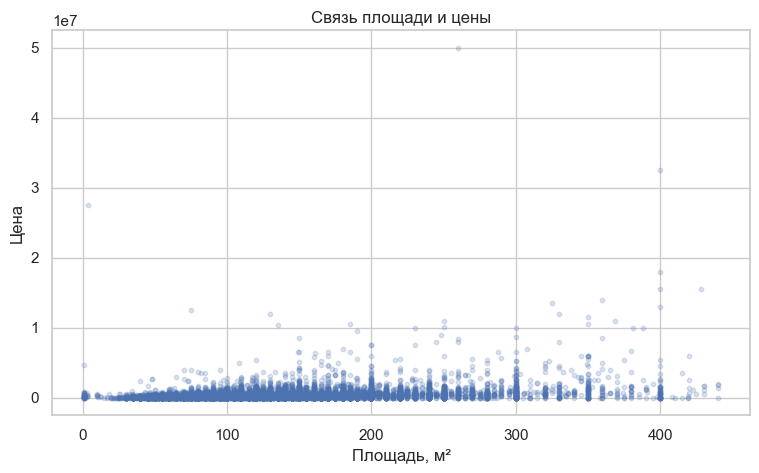

In [8]:
plot_df = df[["площадь_м2", "цена"]].copy()
plot_df["площадь_м2"] = pd.to_numeric(plot_df["площадь_м2"], errors="coerce")
plot_df["цена"] = pd.to_numeric(plot_df["цена"], errors="coerce")
plot_df = plot_df.dropna()
plot_df = plot_df[(plot_df["площадь_м2"] > 0) & (plot_df["цена"] > 0)]
plot_df = plot_df[plot_df["площадь_м2"] <= plot_df["площадь_м2"].quantile(0.99)]
plot_df = plot_df.sample(min(30000, len(plot_df)), random_state=RANDOM_STATE)

plt.figure(figsize=(9, 5))
plt.scatter(plot_df["площадь_м2"], plot_df["цена"], alpha=0.2, s=10)
plt.title("Связь площади и цены")
plt.xlabel("Площадь, м²")
plt.ylabel("Цена")
plt.show()

Проверяем зависимость площади с ценой. При этом для самого графика ограничиваем отображаемую площадь 99-м процентилем — это только визуализация, исходные строки при этом не удаляются

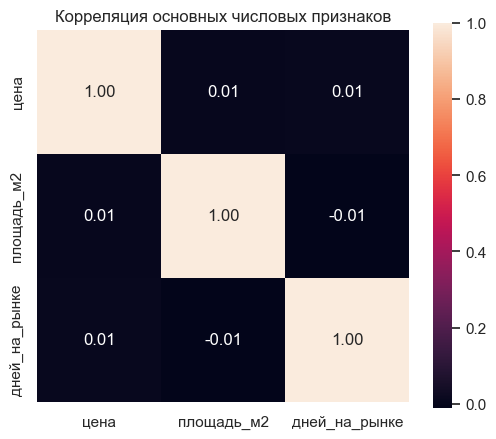

In [9]:
corr_cols = ["цена", "площадь_м2", "дней_на_рынке"]
corr = df[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", square=True)
plt.title("Корреляция основных числовых признаков")
plt.show()

Корреляция показывает, что выраженной линейной зависимости нет, поэтому одной линейной завистимости недостаточно для описания стоимости недвижимости

## 1.4 Категориальные признаки

--- подтип ---


подтип
Квартира                   354549
Вилла                       21324
Отдельный дом                9563
Резиденция                   7716
Дачный дом                   5929
Целое здание                 2607
Сборный дом                   679
Фермерский дом                528
Особняк / усадьба / ялы       301
Квартира в ялы                187
Name: count, dtype: int64

--- тип_отопления ---


тип_отопления
Газовый котёл                                    204150
Кондиционер                                       68197
Центральное отопление с индивидуальным учётом     30595
NaN                                               27970
Центральное отопление                             22855
Газовое отопление                                 10928
Угольная печь                                      8450
Тёплый пол                                         6958
Отсутствует                                        6098
Покомнатное отопление                              5655
Name: count, dtype: int64

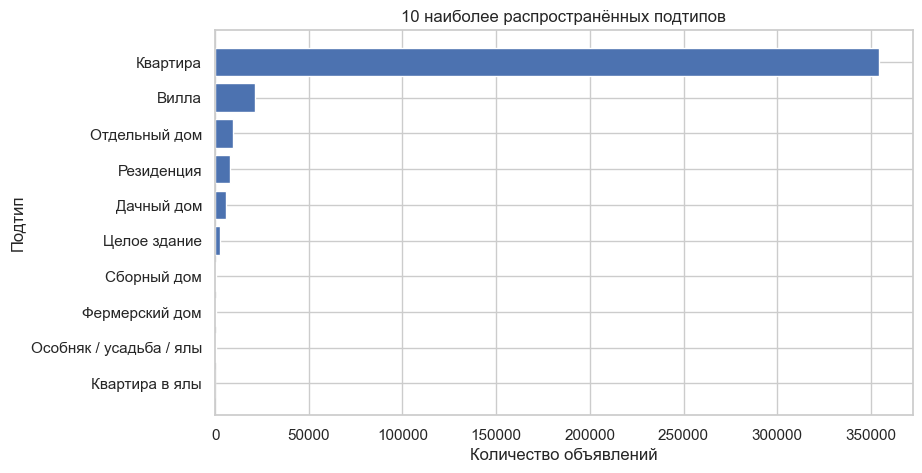

In [10]:
for col in ["подтип", "тип_отопления"]:
    print(f"--- {col} ---")
    display(df[col].value_counts(dropna=False).head(10))

top_subtypes = df["подтип"].value_counts().head(10).sort_values()
plt.figure(figsize=(9, 5))
plt.barh(top_subtypes.index.astype(str), top_subtypes.values)
plt.title("10 наиболее распространённых подтипов")
plt.xlabel("Количество объявлений")
plt.ylabel("Подтип")
plt.show()

Категориальные признаки показывают, какие типы объектов и характеристики отопления реально представлены в выборке. Это важно перед кодированием, чтобы понимать количество категорий и редкие значения

## 1.5 Пропуски, дубликаты и аномалии

,Количество пропусков,"Доля пропусков, %"
мебель,403487,100.00
площадь_м2,146006,36.19
дата_окончания,137189,34.00
этаж,35296,8.75
всего_этажей,28021,6.94
тип_отопления,27970,6.93
возраст_здания,27390,6.79
валюта,715,0.18
цена,715,0.18


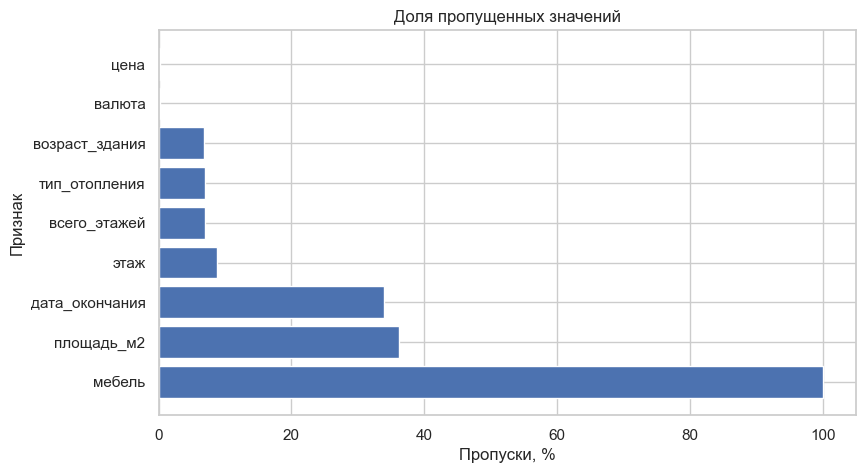

Полных дубликатов: 0
Дубликатов идентификатора: 0


In [11]:
missing = pd.DataFrame({
    "Количество пропусков": df.isna().sum(),
    "Доля пропусков, %": (df.isna().mean() * 100).round(2)
}).sort_values("Количество пропусков", ascending=False)

display(missing[missing["Количество пропусков"] > 0])

plt.figure(figsize=(9, 5))
missing_plot = missing[missing["Количество пропусков"] > 0]
if len(missing_plot):
    plt.barh(missing_plot.index.astype(str), missing_plot["Доля пропусков, %"])
plt.title("Доля пропущенных значений")
plt.xlabel("Пропуски, %")
plt.ylabel("Признак")
plt.show()

print("Полных дубликатов:", df.duplicated().sum())
print("Дубликатов идентификатора:", df["идентификатор"].duplicated().sum())

Пропуски не удаляем механически. Например, отсутствие даты окончания может быть допустимым состоянием активного объявления. Поэтому пропуски в модельных признаках позже обрабатываются внутри Pipeline, а не вручную по всему датасету

In [12]:
checks = pd.Series({
    "Цена < 0": (df["цена"] < 0).sum(),
    "Цена = 0": (df["цена"] == 0).sum(),
    "Площадь < 0": (df["площадь_м2"] < 0).sum(),
    "Площадь > 1000 м²": (df["площадь_м2"] > 1000).sum(),
    "Дней на рынке < 0": (df["дней_на_рынке"] < 0).sum()
}, name="Количество")
display(checks)

Цена < 0               1
Цена = 0              44
Площадь < 0            0
Площадь > 1000 м²    683
Дней на рынке < 0      0
Name: Количество, dtype: int64

Отдельно проверяем очевидно некорректные значения: отрицательные цены, отрицательную площадь и отрицательный срок размещения.

### Вывод по этапу 1

- Исходный набор содержит **403 487 строк и 17 столбцов**.
- В данных присутствуют разные валюты, поэтому для моделирования используется единая валюта — **турецкая лира**.
- Распределение цены сильно скошено, поэтому для обучения используется `log1p(цена)`.
- Проверены категориальные признаки, пропуски, дубликаты и очевидные аномалии.
- На следующем этапе выполняется подготовка признаков без утечки информации из тестовой выборки.

# 2. Предварительная обработка данных

На этом этапе формируем **модельную выборку** и приводим исходные признаки к форме, которую можно передать алгоритмам машинного обучения.

In [13]:
valid_ad_types = ["Продажа", "Аренда"]

model_df = df[
    (df["цена"] > 0) &
    (df["валюта"] == "Турецкая лира") &
    (df["тип_объявления"].isin(valid_ad_types))
].copy()

print("Исходный размер:", df.shape)
print("Размер модельной выборки:", model_df.shape)
print("Потеряно строк при фильтрации:", len(df) - len(model_df))
print("Доля сохранённых строк: %.2f%%" % (len(model_df) / len(df) * 100))

display(model_df["тип_объявления"].value_counts())
display(model_df["валюта"].value_counts())

Исходный размер: (403487, 17)
Размер модельной выборки: (398399, 17)
Потеряно строк при фильтрации: 5088
Доля сохранённых строк: 98.74%


тип_объявления
Продажа    284468
Аренда     113931
Name: count, dtype: int64

валюта
Турецкая лира    398399
Name: count, dtype: int64

Из 403 487 исходных строк после обоснованной фильтрации осталось 398 399 объектов. Убираем записи с неположительной ценой, другой валютой и неподходящим типом объявления. Это нужно, чтобы целевая переменная была сопоставима

Типы объявлений после очистки:


тип_объявления
Продажа    287009
Аренда     114236
Name: count, dtype: int64

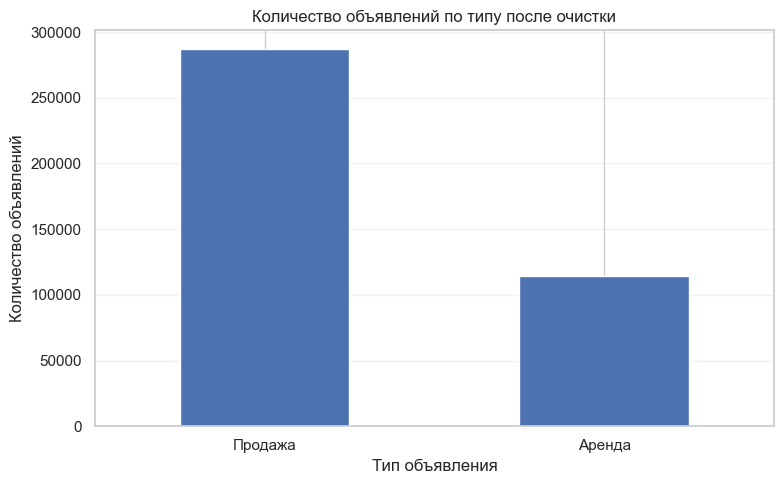

In [14]:
valid_ad_types = ["Продажа", "Аренда"]

clean_ad_types = df[
    df["тип_объявления"].isin(valid_ad_types)
]["тип_объявления"].value_counts()

# Выводим результат
print("Типы объявлений после очистки:")
display(clean_ad_types)

# Строим график
plt.figure(figsize=(8, 5))

clean_ad_types.plot(kind="bar")

plt.title("Количество объявлений по типу после очистки")
plt.xlabel("Тип объявления")
plt.ylabel("Количество объявлений")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

## 2.1 Проверка выбросов 

1-й процентиль цены: 550 TRY
99-й процентиль цены: 2,850,000 TRY
Ниже 1-го процентиля: 0.80%
Выше 99-го процентиля: 0.99%


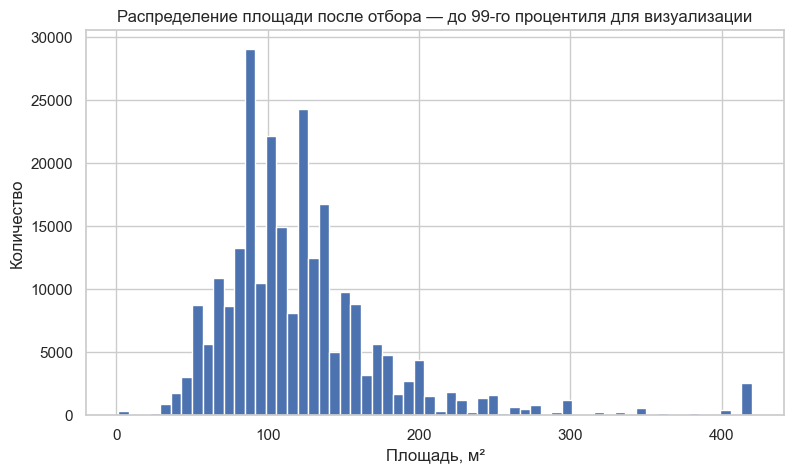

In [15]:
q01 = model_df["цена"].quantile(0.01)
q99 = model_df["цена"].quantile(0.99)

print(f"1-й процентиль цены: {q01:,.0f} TRY")
print(f"99-й процентиль цены: {q99:,.0f} TRY")
print(f"Ниже 1-го процентиля: {(model_df['цена'] < q01).mean()*100:.2f}%")
print(f"Выше 99-го процентиля: {(model_df['цена'] > q99).mean()*100:.2f}%")

plt.figure(figsize=(9, 5))
plt.hist(model_df["площадь_м2"].clip(upper=model_df["площадь_м2"].quantile(0.99)), bins=60)
plt.title("Распределение площади после отбора — до 99-го процентиля для визуализации")
plt.xlabel("Площадь, м²")
plt.ylabel("Количество")
plt.show()

Процентиль здесь используется для диагностики и визуализации, а не для удаления тестовых объектов. Больше всего от 60 до 150. Больше 150 кол-во объявлений уменьшается. Присутствуют отдельные крупные объекты.

## 2.2 Преобразование диапазонов, комнат и этажа

In [16]:
def range_to_number(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    if s.isdigit():
        return float(s)
    m = re.match(r"^(\d+)\s*-\s*(\d+)$", s)
    if m:
        return (int(m.group(1)) + int(m.group(2))) / 2
    if "и более" in s:
        m = re.search(r"\d+", s)
        return float(m.group()) if m else np.nan
    return np.nan


def room_to_number(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    m = re.match(r"^(\d+)\+(\d+)$", s)
    if m:
        return int(m.group(1)) + int(m.group(2))
    if s.isdigit():
        return float(s)
    return np.nan

model_df["возраст_число"] = model_df["возраст_здания"].apply(range_to_number)
model_df["этажей_число"] = model_df["всего_этажей"].apply(range_to_number)
model_df["этаж_число"] = model_df["этаж"].apply(range_to_number)
model_df["комнаты_число"] = model_df["комнаты"].apply(room_to_number)
model_df["этаж_категория"] = model_df["этаж"].astype(object).where(model_df["этаж"].notna(), "Не указано")

display(model_df[[
    "возраст_здания", "возраст_число",
    "всего_этажей", "этажей_число",
    "этаж", "этаж_число", "этаж_категория",
    "комнаты", "комнаты_число"
]].head(10))

,возраст_здания,возраст_число,всего_этажей,этажей_число,этаж,этаж_число,этаж_категория,комнаты,комнаты_число
0,Новое здание,NaN,20 и более,20.0,2,2.0,2,2+1,3.0
1,Новое здание,NaN,20 и более,20.0,20 ve üzeri,NaN,20 ve üzeri,1+0,1.0
2,Новое здание,NaN,1,1.0,Yüksek Giriş,NaN,Yüksek Giriş,2+1,3.0
3,3,3.0,20 и более,20.0,20 ve üzeri,NaN,20 ve üzeri,6+1,7.0
4,Новое здание,NaN,20 и более,20.0,2,2.0,2,2+1,3.0
5,2,2.0,10-20,15.0,10,10.0,10,1+1,2.0
6,Новое здание,NaN,20 и более,20.0,14,14.0,14,3+1,4.0
7,Новое здание,NaN,4,4.0,NaN,NaN,Не указано,4+1,5.0
8,NaN,NaN,2,2.0,Kot 2,NaN,Kot 2,3+1,4.0
10,Новое здание,NaN,1,1.0,Bahçe katı,NaN,Bahçe katı,3+1,4.0


Исходные признаки содержат диапазоны и текстовые значения. Создаем числовые версии, чтобы алгоритм мог работать с ними. При этом для этажа сохраняем и числовое значение, и категорию: например, “садовый этаж” или “подвальный этаж” имеют смысл, который нельзя полностью заменить одним числом.

## 2.3 Feature Engineering: дата и адрес

In [17]:
# В датасете встречаются разные форматы дат, поэтому используем mixed.
model_df["дата_начала"] = pd.to_datetime(
    model_df["дата_начала"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

model_df["год_начала"] = model_df["дата_начала"].dt.year
model_df["месяц_начала"] = model_df["дата_начала"].dt.month

address_parts = model_df["адрес"].astype(object).where(
    model_df["адрес"].notna(), np.nan
).astype(str).str.split("/", expand=True)

model_df["город"] = address_parts[0].replace("nan", np.nan).str.strip()
model_df["район"] = address_parts[1].replace("nan", np.nan).str.strip()

display(model_df[[
    "дата_начала", "год_начала", "месяц_начала",
    "адрес", "город", "район"
]].head(10))

,дата_начала,год_начала,месяц_начала,адрес,город,район
0,2018-10-12,2018,10,Стамбул/Картал/Кордонбойу,Стамбул,Картал
1,2019-02-13,2019,2,Стамбул/Картал/Кордонбойу,Стамбул,Картал
2,2018-09-10,2018,9,Текирдаг/Чорлу/Решадийе,Текирдаг,Чорлу
3,2018-10-09,2018,10,Стамбул/Бешикташ/Левент,Стамбул,Бешикташ
4,2018-10-12,2018,10,Стамбул/Картал/Кордонбойу,Стамбул,Картал
5,2018-09-11,2018,9,Стамбул/Малтепе/Алтайчешме,Стамбул,Малтепе
6,2019-04-01,2019,4,Стамбул/Картал/Кордонбойу,Стамбул,Картал
7,2018-03-10,2018,3,Измир/Урла/М. Февзи Чакмак,Измир,Урла
8,2019-02-16,2019,2,Чанаккале/Айваджык/Кючюккуйу Блд. (Мыхлы),Чанаккале,Айваджык
10,2018-11-13,2018,11,Мугла/Бодрум/Ортакентйахши,Мугла,Бодрум


Из даты выделяем год и месяц публикации, потому что исходную дату в строковом виде модели использовать неудобно. Из адреса выделяем город и район — это важные признаки для недвижимости, поскольку расположение существенно связано со стоимостью.

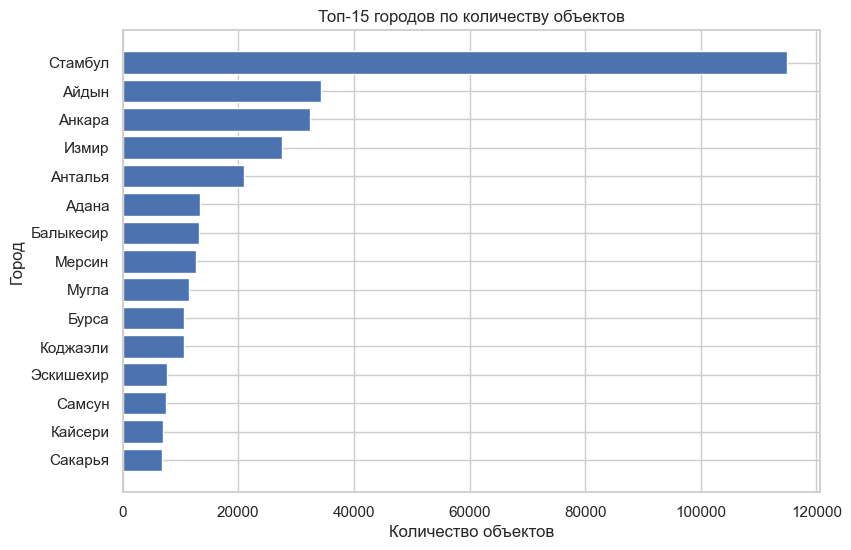

In [18]:
city_counts = model_df["город"].value_counts().head(15).sort_values()

plt.figure(figsize=(9, 6))
plt.barh(city_counts.index.astype(str), city_counts.values)
plt.title("Топ-15 городов по количеству объектов")
plt.xlabel("Количество объектов")
plt.ylabel("Город")
plt.show()


После выделения города проверяем распределение объектов по регионам. Это важно, потому что выборка по городам неоднородна: некоторые города представлены большим числом объявлений, а другие — значительно меньшим. Поэтому город и район используются как категориальные признаки модели

## 2.4 Формирование финальных 15 признаков

In [19]:
FEATURES = [
    "тип_недвижимости",
    "подтип",
    "тип_объявления",
    "дней_на_рынке",
    "площадь_м2",
    "тип_отопления",
    "возраст_число",
    "этажей_число",
    "этаж_число",
    "этаж_категория",
    "комнаты_число",
    "год_начала",
    "месяц_начала",
    "город",
    "район"
]

X = model_df[FEATURES].copy()
y = model_df["цена"].copy()

categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

# Приводим категориальные столбцы к обычному object/np.nan,
# чтобы SimpleImputer и Encoder одинаково работали в разных версиях pandas/sklearn.
for col in categorical_features:
    X[col] = X[col].astype(object).where(pd.notna(X[col]), np.nan)

print("Количество признаков:", len(FEATURES))
print("Категориальные:", categorical_features)
print("Числовые:", numeric_features)
print("Размер X:", X.shape)
print("Размер y:", y.shape)

Количество признаков: 15
Категориальные: ['тип_недвижимости', 'подтип', 'тип_объявления', 'тип_отопления', 'этаж_категория', 'город', 'район']
Числовые: ['дней_на_рынке', 'площадь_м2', 'возраст_число', 'этажей_число', 'этаж_число', 'комнаты_число', 'год_начала', 'месяц_начала']
Размер X: (398399, 15)
Размер y: (398399,)


В финальную модель передаем 15 признаков. Явно задаем их список, чтобы избежать случайного попадания служебных полей. Идентификатор, исходный адрес, исходная дата, валюта и сама цена в признаки не входят — цена является целевой переменной.

## 2.5 Проверка пропусков после Feature Engineering

In [20]:
prep_check = pd.DataFrame({
    "Тип": X.dtypes.astype(str),
    "Пропуски": X.isna().sum(),
    "Доля пропусков, %": (X.isna().mean()*100).round(2)
})
display(prep_check)

,Тип,Пропуски,"Доля пропусков, %"
тип_недвижимости,object,0,0.00
подтип,object,0,0.00
тип_объявления,object,0,0.00
дней_на_рынке,int64,0,0.00
площадь_м2,float64,143406,36.00
тип_отопления,object,27066,6.79
возраст_число,float64,165677,41.59
этажей_число,float64,27194,6.83
этаж_число,float64,137300,34.46
этаж_категория,object,0,0.00


После создания признаков ещё раз проверяем пропуски. Не заполняем их до разбиения train/test вручную, потому что тогда статистика могла бы использовать информацию из теста. Заполнение будет выполняться внутри Pipeline, обучаясь только на train.

## 2.6 Train/Test split

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Train:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)
print("Доля test: %.1f%%" % (len(X_test) / len(X) * 100))

Train: (318719, 15) (318719,)
Test: (79680, 15) (79680,)
Доля test: 20.0%


Откладываем 20 процентов данных в тестовую выборку. `random_state=42` фиксирует разбиение, поэтому эксперимент воспроизводим. Тестовая выборка не используется для подгонки препроцессоров и гиперпараметров.

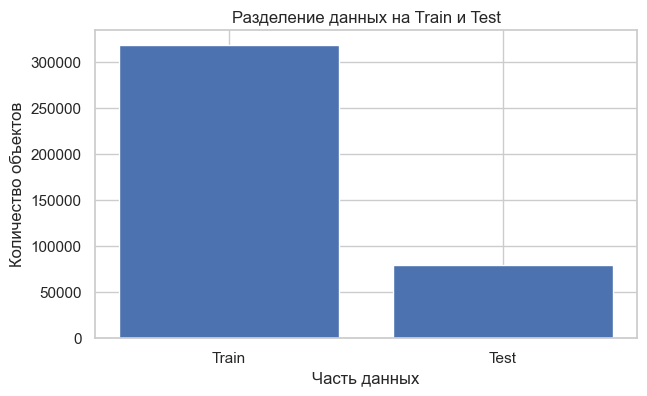

In [22]:
split_df = pd.DataFrame({
    "Выборка": ["Train", "Test"],
    "Количество": [len(X_train), len(X_test)]
})

plt.figure(figsize=(7, 4))
plt.bar(split_df["Выборка"], split_df["Количество"])
plt.title("Разделение данных на Train и Test")
plt.xlabel("Часть данных")
plt.ylabel("Количество объектов")
plt.show()


График подтверждает фактическое разбиение данных: 80 процентов объектов используются для обучения, 20 процентов остаются для независимой проверки. Это визуальная проверка того, что тестовая выборка действительно отделена.


In [23]:
preprocessor_scaled = ColumnTransformer([
    (
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        numeric_features
    ),
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_features
    )
])

preprocessor_tree = ColumnTransformer([
    (
        "num",
        SimpleImputer(strategy="median"),
        numeric_features
    ),
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            (
                "encoder",
                OrdinalEncoder(
                    handle_unknown="use_encoded_value",
                    unknown_value=-1
                )
            )
        ]),
        categorical_features
    )
])

print("Pipeline для Linear Regression готов.")
print("Pipeline для деревьев/LightGBM готов.")

Pipeline для Linear Regression готов.
Pipeline для деревьев/LightGBM готов.


Для линейной регрессии числовые признаки масштабируются, а категориальные кодируются One-Hot. Для деревьев и LightGBM масштабирование не требуется, поэтому используется отдельный препроцессор с OrdinalEncoder. Все эти преобразования находятся внутри Pipeline, поэтому они обучаются только на тренировочных данных.

## 2.8 Логарифмирование целевой переменной

In [24]:
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

print("Целевая переменная преобразована: y_log = log(1 + цена)")
print("Минимум y_log:", y_train_log.min())
print("Максимум y_log:", y_train_log.max())

Целевая переменная преобразована: y_log = log(1 + цена)
Минимум y_log: 0.6931471805599453
Максимум y_log: 21.416413018006356


Модель обучается на `log(1 + цена)`, потому что цена имеет большой диапазон и сильную асимметрию. При оценке возвращаем прогноз в исходную шкалу через `expm1`, поэтому MAE и RMSE интерпретируются в турецких лирах».

### Вывод по этапу 2

В результате получена модельная выборка из **398 399 объектов**. Созданы 15 финальных признаков, в том числе числовые представления диапазонов, категория этажа, год/месяц публикации, город и район. Пропуски и кодирование выполняются внутри Pipeline, а данные разделены на train/test до обучения препроцессоров.

# 3. Построение моделей регрессии

Сравним модели разной природы:

1. **Linear Regression** — простая базовая модель.
2. **Decision Tree** — одно дерево решений.
3. **Random Forest** — ансамбль деревьев, бэггинг.
4. **LightGBM** — градиентный бустинг по деревьям.

Наличие нескольких моделей позволяет понять, насколько нелинейные ансамблевые методы полезны для данной задачи.

In [25]:
models = {
    "Linear Regression": Pipeline([
        ("prep", preprocessor_scaled),
        ("model", LinearRegression())
    ]),
    "Decision Tree": Pipeline([
        ("prep", preprocessor_tree),
        ("model", DecisionTreeRegressor(
            max_depth=15,
            min_samples_leaf=3,
            random_state=RANDOM_STATE
        ))
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocessor_tree),
        ("model", RandomForestRegressor(
            n_estimators=30,
            max_depth=15,
            min_samples_leaf=3,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]),
    "LightGBM": Pipeline([
        ("prep", preprocessor_tree),
        ("model", LGBMRegressor(
            objective="regression",
            n_estimators=1200,
            learning_rate=0.04,
            num_leaves=63,
            min_child_samples=60,
            subsample=0.85,
            colsample_bytree=0.90,
            reg_alpha=0.05,
            reg_lambda=1.0,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbosity=-1
        ))
    ])
}

for name in models:
    print("-", name)

- Linear Regression
- Decision Tree
- Random Forest
- LightGBM


Для всех моделей одинаковая целевая переменная и одинаковое train/test-разбиение. Отличается только алгоритм и необходимая ему предобработка. Это делает сравнение корректным.

## 3.1 Базовое обучение

In [26]:
def evaluate_predictions(y_true, pred):
    return {
        "MAE": mean_absolute_error(y_true, pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, pred)),
        "MAPE, %": np.mean(np.abs((y_true.to_numpy() - pred) / y_true.to_numpy())) * 100,
        "R²": r2_score(y_true, pred),
        "Медианная абсолютная ошибка": median_absolute_error(y_true, pred)
    }

baseline_results = []
baseline_predictions = {}

for name, model in models.items():
    print(f"Обучение: {name}")
    model.fit(X_train, y_train_log)
    pred_log = model.predict(X_test)
    pred = np.maximum(np.expm1(pred_log), 0)
    baseline_predictions[name] = pred
    row = {"Модель": name}
    row.update(evaluate_predictions(y_test, pred))
    baseline_results.append(row)

baseline_df = pd.DataFrame(baseline_results).sort_values("MAE")
display(baseline_df)

Обучение: Linear Regression
Обучение: Decision Tree
Обучение: Random Forest
Обучение: LightGBM


C:\Users\Honor\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Модель,MAE,RMSE,"MAPE, %",R²,Медианная абсолютная ошибка
3,LightGBM,111449.584404,1.052528e+06,872.616177,0.402856,24009.500446
2,Random Forest,116341.366112,1.043261e+06,876.915872,0.413325,26947.949730
1,Decision Tree,128640.131009,1.238972e+06,904.121220,0.172563,27990.404293
0,Linear Regression,138280.939075,1.191024e+06,656.157817,0.235367,29975.603924


## 3.2 Подготовка итоговой конфигурации


In [27]:
# ============================================================
# Фиксируем конфигурации, которые уже использовались на этапе 3.1
# ============================================================
# Важно: это не автоматический подбор гиперпараметров.
# На этапе 3.1 модели уже обучались с этими конфигурациями.
# Здесь мы явно сохраняем их для воспроизводимости и дальнейшего использования.

best_models = {name: model for name, model in models.items()}

best_params = {
    "Linear Regression": {
        "fit_intercept": True
    },
    "Decision Tree": {
        "max_depth": 15,
        "min_samples_leaf": 3,
        "random_state": RANDOM_STATE
    },
    "Random Forest": {
        "n_estimators": 30,
        "max_depth": 15,
        "min_samples_leaf": 3,
        "random_state": RANDOM_STATE
    },
    "LightGBM": {
        "n_estimators": 1200,
        "learning_rate": 0.04,
        "num_leaves": 63,
        "min_child_samples": 60,
        "subsample": 0.85,
        "colsample_bytree": 0.90,
        "reg_alpha": 0.05,
        "reg_lambda": 1.0,
        "random_state": RANDOM_STATE
    }
}

print("Конфигурации моделей зафиксированы для воспроизводимости.")


Конфигурации моделей зафиксированы для воспроизводимости.


Базовое обучение и первичное сравнение выполнены в разделе 3.1. На этом этапе параметры моделей не подбирались автоматически. В разделе 3.2 фиксированные значения явно сохраняются для воспроизводимости и согласованного использования модели в приложении.


## 3.2.1 Параметры моделей


Ниже приведены параметры, с которыми модели были обучены на этапе 3.1. Для LightGBM зафиксирована production-конфигурация, которая затем используется в `model.pkl` и приложении.


In [28]:
# У разных алгоритмов разные гиперпараметры.
# Поэтому не выводим их как широкую таблицу — иначе появляются NaN.
# Вместо этого показываем компактно: одна модель → её настройки.

params_rows = []

for name, params in best_params.items():

    # Убираем технический префикс Pipeline "model__"
    clean_params = {
        key.replace("model__", ""): value
        for key, value in params.items()
    }

    # Превращаем параметры в одну понятную строку
    params_text = "; ".join(
        f"{key} = {value}"
        for key, value in clean_params.items()
    )

    params_rows.append({
        "Модель": name,
        "Настройки": params_text
    })

params_df = pd.DataFrame(params_rows)

display(params_df)

,Модель,Настройки
0,Linear Regression,fit_intercept = True
1,Decision Tree,max_depth = 15; min_samples_leaf = 3; random_s...
2,Random Forest,n_estimators = 30; max_depth = 15; min_samples...
3,LightGBM,n_estimators = 1200; learning_rate = 0.04; num...


Тестовая выборка не использовалась для обучения моделей. Она была отложена на этапе разбиения данных и применяется только для независимой оценки качества.


In [29]:
# Повторно обучать модели здесь не требуется: они уже обучены в разделе 3.1.
# Проверяем, что все четыре модели готовы к итоговой оценке.

for name, model in best_models.items():
    print(f"{name}: модель готова")


Linear Regression: модель готова
Decision Tree: модель готова
Random Forest: модель готова
LightGBM: модель готова


Таким образом, после базового обучения мы не выполняем скрытого повторного подбора. Сохраняем прозрачную последовательность: базовое обучение → фиксация конфигураций → итоговая оценка на отложенной тестовой выборке.


## 3.3 Итоговые метрики


In [30]:
results = []
predictions = {}

for name, model in best_models.items():
    pred_log = model.predict(X_test)
    pred = np.maximum(np.expm1(pred_log), 0)
    predictions[name] = pred
    row = {"Модель": name}
    row.update(evaluate_predictions(y_test, pred))
    results.append(row)

results_df = pd.DataFrame(results).sort_values("MAE").reset_index(drop=True)
display(results_df.style.format({
    "MAE": "{:,.0f}",
    "RMSE": "{:,.0f}",
    "MAPE, %": "{:.2f}",
    "R²": "{:.3f}",
    "Медианная абсолютная ошибка": "{:,.0f}"
}))

C:\Users\Honor\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Модель,MAE,RMSE,"MAPE, %",R²,Медианная абсолютная ошибка
0,LightGBM,"111,450","1,052,528",872.62,0.403,"24,010"
1,Random Forest,"116,341","1,043,261",876.92,0.413,"26,948"
2,Decision Tree,"128,640","1,238,972",904.12,0.173,"27,990"
3,Linear Regression,"138,281","1,191,024",656.16,0.235,"29,976"


Основной показатель — MAE: он показывает среднюю абсолютную ошибку непосредственно в турецких лирах. RMSE сильнее учитывает крупные ошибки, MAPE показывает относительную ошибку, а R² характеризует долю объяснённой вариации целевой переменной.


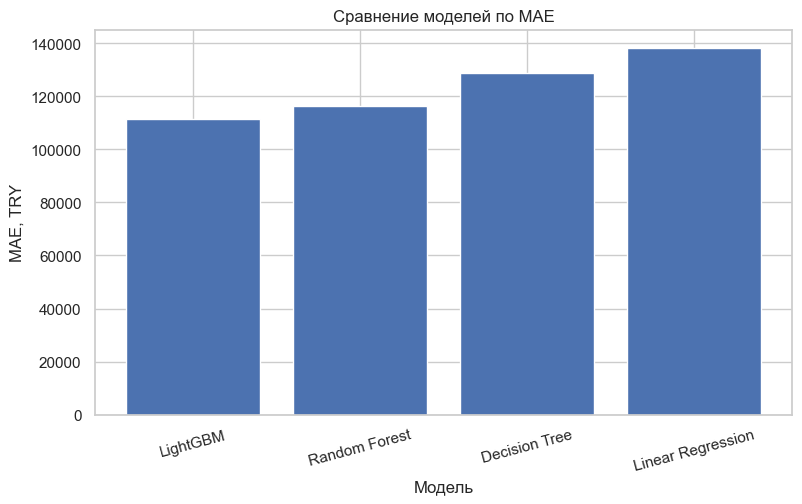

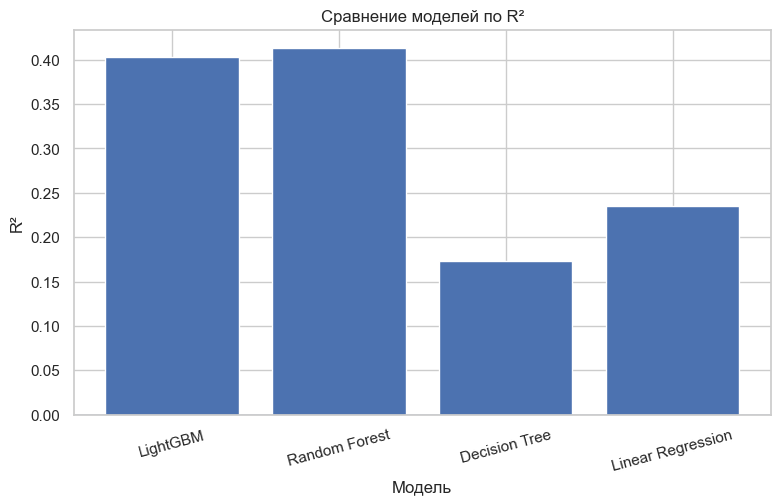

In [31]:
plt.figure(figsize=(9, 5))
plt.bar(results_df["Модель"], results_df["MAE"])
plt.title("Сравнение моделей по MAE")
plt.xlabel("Модель")
plt.ylabel("MAE, TRY")
plt.xticks(rotation=15)
plt.show()

plt.figure(figsize=(9, 5))
plt.bar(results_df["Модель"], results_df["R²"])
plt.title("Сравнение моделей по R²")
plt.xlabel("Модель")
plt.ylabel("R²")
plt.xticks(rotation=15)
plt.axhline(0, linewidth=1)
plt.show()

Визуализируем две ключевые метрики отдельно. Чем меньше MAE, тем меньше средняя абсолютная ошибка. Для R² значения ближе к единице лучше;

## 3.3.1 Качество отдельно для продажи и аренды

In [32]:
best_name = "LightGBM"
best_pred = predictions[best_name]

group_metrics = []
for ad_type in ["Продажа", "Аренда"]:
    mask = X_test["тип_объявления"].eq(ad_type)
    if mask.sum() == 0:
        continue
    actual = y_test.loc[mask]
    pred = best_pred[mask.to_numpy()]
    group_metrics.append({
        "Тип объявления": ad_type,
        "Количество": len(actual),
        "MAE": mean_absolute_error(actual, pred),
        "RMSE": np.sqrt(mean_squared_error(actual, pred)),
        "MAPE, %": np.mean(np.abs((actual.to_numpy()-pred)/actual.to_numpy()))*100,
        "R²": r2_score(actual, pred)
    })

group_metrics_df = pd.DataFrame(group_metrics)
display(group_metrics_df.style.format({"MAE":"{:,.0f}","RMSE":"{:,.0f}","MAPE, %":"{:.2f}","R²":"{:.3f}"}))

,Тип объявления,Количество,MAE,RMSE,"MAPE, %",R²
0,Продажа,56908,"155,011","1,241,289",1205.32,0.390
1,Аренда,22772,"2,587","160,545",41.19,0.002


Отдельно проверяем продажу и аренду, потому что эти два типа объявлений имеют разный масштаб цен. Это позволяет понять, не скрывается ли плохое качество одной группы внутри общей метрики.

## 3.4 Визуальный анализ качества

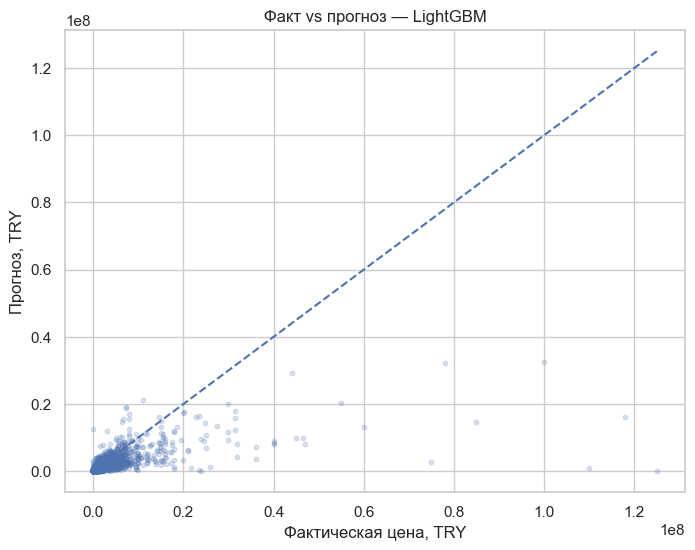

In [33]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, best_pred, alpha=0.2, s=10)
min_value = min(y_test.min(), best_pred.min())
max_value = max(y_test.max(), best_pred.max())
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")
plt.title(f"Факт vs прогноз — {best_name}")
plt.xlabel("Фактическая цена, TRY")
plt.ylabel("Прогноз, TRY")
plt.show()

Диагональ соответствует идеальному прогнозу. Чем ближе точки к ней, тем меньше ошибка. Большой разброс точек показывает, что задача недвижимости сложная и модель не объясняет всю вариативность цен».

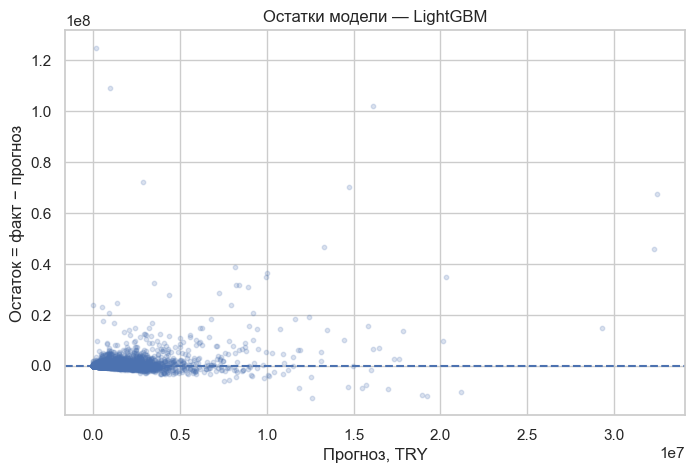

In [34]:
residuals = y_test.to_numpy() - best_pred

plt.figure(figsize=(8, 5))
plt.scatter(best_pred, residuals, alpha=0.2, s=10)
plt.axhline(0, linestyle="--")
plt.title(f"Остатки модели — {best_name}")
plt.xlabel("Прогноз, TRY")
plt.ylabel("Остаток = факт − прогноз")
plt.show()

Остаток — это разница между фактической ценой и прогнозом. В идеале точки должны располагаться вокруг нулевой линии без явного систематического рисунка.

## 3.4.1 Распределение абсолютной ошибки

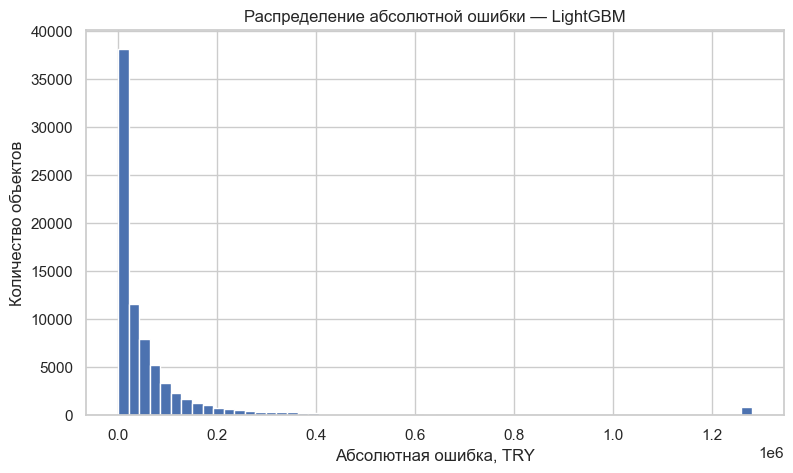

In [35]:
# Формируем таблицу ошибок для текущей модели LightGBM.
# error_df не создавался в предыдущих ячейках, поэтому рассчитываем его здесь.
error_df = pd.DataFrame({
    "Фактическая цена": np.asarray(y_test),
    "Прогноз": np.asarray(best_pred)
})
error_df["Абсолютная ошибка"] = np.abs(
    error_df["Фактическая цена"] - error_df["Прогноз"]
)

plt.figure(figsize=(9, 5))
upper_limit = error_df["Абсолютная ошибка"].quantile(0.99)
plt.hist(error_df["Абсолютная ошибка"].clip(upper=upper_limit), bins=60)
plt.title(f"Распределение абсолютной ошибки — {best_name}")
plt.xlabel("Абсолютная ошибка, TRY")
plt.ylabel("Количество объектов")
plt.show()


Для наглядности показываем распределение абсолютной ошибки. Здесь также ограничена только визуальная область до 99-го процентиля, чтобы редкие экстремальные ошибки не сжимали весь график.

Большинство прогнозов имеют относительно небольшую абсолютную ошибку. При этом присутствуют отдельные экстремальные значения, связанные с редкими объектами, поэтому распределение имеет длинный правый хвост.

## 3.4.2 Важность признаков LightGBM

,Признак,Важность
14,cat__район,15563
1,num__площадь_м2,8984
13,cat__город,8417
0,num__дней_на_рынке,5888
3,num__этажей_число,5529
12,cat__этаж_категория,4838
11,cat__тип_отопления,4826
5,num__комнаты_число,4725
2,num__возраст_число,4268
7,num__месяц_начала,3720


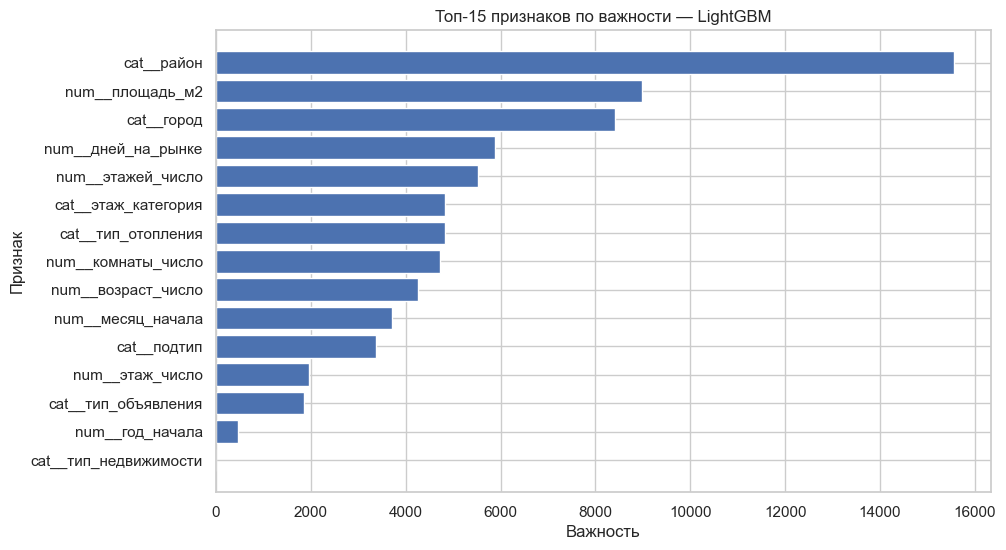

In [36]:
lgbm_model = best_models["LightGBM"]
feature_names = lgbm_model.named_steps["prep"].get_feature_names_out()
importances = lgbm_model.named_steps["model"].feature_importances_

importance_df = pd.DataFrame({
    "Признак": feature_names,
    "Важность": importances
}).sort_values("Важность", ascending=False)

display(importance_df.head(20))

top_importance = importance_df.head(15).sort_values("Важность")
plt.figure(figsize=(10, 6))
plt.barh(top_importance["Признак"], top_importance["Важность"])
plt.title("Топ-15 признаков по важности — LightGBM")
plt.xlabel("Важность")
plt.ylabel("Признак")
plt.show()

После обучения смотрим относительную важность признаков LightGBM. Это помогает понять, какие характеристики модель чаще использует при построении решений. Важность не означает причинно-следственную связь — это показатель вклада признака в работу модели».

## 3.5 Выбор финальной production-модели


In [37]:
# По тестовым метрикам отдельно фиксируем результаты сравнения.
# В текущем наборе минимальный MAE имеет модель, указанная ниже.
metric_best_name = results_df.loc[results_df["MAE"].idxmin(), "Модель"]
print("Минимальный MAE на тестовой выборке:", metric_best_name)
display(results_df[results_df["Модель"] == metric_best_name])

# Для приложения используем LightGBM, потому что именно эта
# production-конфигурация заранее согласована с интерфейсом приложения.
production_model_name = "LightGBM"
print("\nProduction-модель для приложения:", production_model_name)
print("Важно: выбор production-модели не выдаётся за результат автоматического подбора.")


Минимальный MAE на тестовой выборке: LightGBM


,Модель,MAE,RMSE,"MAPE, %",R²,Медианная абсолютная ошибка
0,LightGBM,111449.584404,1.052528e+06,872.616177,0.402856,24009.500446



Production-модель для приложения: LightGBM
Важно: выбор production-модели не выдаётся за результат автоматического подбора.


По тестовым метрикам модели отличаются по нескольким показателям, поэтому не утверждаем, что одна модель является лучшей сразу по всем критериям. Для приложения фиксируется LightGBM с заранее определённой конфигурацией, одинаковой в ноутбуке и в `model.pkl`.


## 3.5.1 Финальное обучение и сохранение Pipeline

In [38]:
# ============================================================
# Финальный Pipeline для приложения
# ============================================================
# Используем ту же конфигурацию LightGBM, которая была зафиксирована выше.
# Preprocessing находится внутри Pipeline, поэтому при прогнозировании
# новых объектов применяется та же последовательность преобразований.

final_model = Pipeline([
    ("prep", preprocessor_tree),
    ("model", LGBMRegressor(
        objective="regression",
        n_estimators=1200,
        learning_rate=0.04,
        num_leaves=63,
        min_child_samples=60,
        subsample=0.85,
        colsample_bytree=0.90,
        reg_alpha=0.05,
        reg_lambda=1.0,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=-1
    ))
])

# После независимой оценки на test production-модель обучается
# на полном доступном наборе данных. Это не меняет уже рассчитанные
# тестовые метрики и делается только после завершения оценки.
final_model.fit(X, np.log1p(y))

MODEL_FILE = "model.pkl"
joblib.dump(final_model, MODEL_FILE)

print("Сохранено:", MODEL_FILE)
print("Количество входных признаков:", len(final_model.feature_names_in_))
print("Признаки:")
print(list(final_model.feature_names_in_))


Сохранено: model.pkl
Количество входных признаков: 15
Признаки:
['тип_недвижимости', 'подтип', 'тип_объявления', 'дней_на_рынке', 'площадь_м2', 'тип_отопления', 'возраст_число', 'этажей_число', 'этаж_число', 'этаж_категория', 'комнаты_число', 'год_начала', 'месяц_начала', 'город', 'район']


## 3.5.2 Проверка сохранённой модели

In [39]:
loaded_model = joblib.load(MODEL_FILE)

check_pred_log = loaded_model.predict(X_test.head(5))
check_pred = np.maximum(np.expm1(check_pred_log), 0)

check_df = pd.DataFrame({
    "Фактическая цена": y_test.head(5).to_numpy(),
    "Прогноз сохранённой модели": check_pred
})
display(check_df)

print("Pipeline успешно загружается из model.pkl.")

C:\Users\Honor\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Фактическая цена,Прогноз сохранённой модели
0,2500.0,2686.299391
1,279000.0,216772.295565
2,2500.0,2759.716182
3,1150.0,1073.047060
4,125000.0,158063.374320


Pipeline успешно загружается из model.pkl.


Проверяем не только обучение, но и сам сохранённый файл. После загрузки `model.pkl` модель принимает те же 15 признаков и выдаёт прогноз. Это подтверждает готовность модели к использованию в Streamlit.


# 4. Проверка LightGBM на 20 новых объектах недвижимости

В этом разделе проверяется сохранённая production-модель LightGBM на отдельном файле `test_real_estate_samples.csv`, содержащем 20 **синтетических** объектов недвижимости. Характеристики и условные фактические цены созданы для учебного задания, а не взяты из независимой рыночной выборки. Поэтому результаты показывают поведение модели на заданных примерах и не являются доказательством точности на реальном рынке.

Используются те же 15 признаков, что и при обучении. Преобразования категориальных и числовых данных выполняются внутри ранее обученного Pipeline.


In [45]:
STUDENT_NAME = "Псянчин Аскар Азатович"
STUDENT_GROUP = "23П-2"
TEST_FILE = "test_real_estate_samples.csv"
RESULT_FILE = "result_real_estate_samples.csv"

# Загружаем отдельную тестовую выборку
test_samples = pd.read_csv(TEST_FILE)

# Проверяем, что в файле есть все входные признаки и фактическая цена
required_columns = FEATURES + ["цена"]
missing_columns = [col for col in required_columns if col not in test_samples.columns]
if missing_columns:
    raise ValueError(f"В тестовом файле отсутствуют столбцы: {missing_columns}")
if len(test_samples) != 20:
    raise ValueError(f"Ожидалось 20 тестовых объектов, получено: {len(test_samples)}")

X_samples = test_samples[FEATURES].copy()
# В обучающем наборе категориальные признаки были строковыми.
# Приводим их к такому же виду (например, этаж_категория), сохраняя пропуски.
for col in categorical_features:
    X_samples[col] = X_samples[col].map(lambda value: str(value) if pd.notna(value) else np.nan).astype(object)
y_true = pd.to_numeric(test_samples["цена"], errors="raise").to_numpy(dtype=float)

# Используем уже обученную и загруженную в предыдущем разделе модель
predicted_log = loaded_model.predict(X_samples)
y_pred = np.maximum(np.expm1(predicted_log), 0)

print("Файл:", TEST_FILE)
print("Количество тестовых объектов:", len(test_samples))
print("Используемая модель: LightGBM Pipeline")


Файл: test_real_estate_samples.csv
Количество тестовых объектов: 20
Используемая модель: LightGBM Pipeline


C:\Users\Honor\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


## 4.1 Таблица фактических и прогнозируемых цен

Для каждого объекта сохраняются исходные характеристики, условная фактическая цена, ошибка прогноза, ФИО и группа. Столбец **«Прогноз модели, TRY»** расположен последним, как требует задание.


In [46]:
result_df = test_samples.copy()
result_df["Абсолютная ошибка, TRY"] = np.abs(y_true - y_pred)
result_df["Квадрат ошибки, TRY²"] = (y_true - y_pred) ** 2
result_df["ФИО"] = STUDENT_NAME
result_df["Группа"] = STUDENT_GROUP
result_df["Прогноз модели, TRY"] = np.round(y_pred, 2)

# Сохраняем CSV в UTF-8 с BOM, чтобы кириллица корректно открывалась в Excel
result_df.to_csv(RESULT_FILE, index=False, encoding="utf-8-sig")

print("Итоговый файл сохранён:", RESULT_FILE)
display(result_df.style.format({
    "цена": "{:,.0f}",
    "Абсолютная ошибка, TRY": "{:,.2f}",
    "Квадрат ошибки, TRY²": "{:,.2f}",
    "Прогноз модели, TRY": "{:,.2f}"
}))


Итоговый файл сохранён: result_real_estate_samples.csv


,тип_недвижимости,подтип,тип_объявления,дней_на_рынке,площадь_м2,тип_отопления,возраст_число,этажей_число,этаж_число,этаж_категория,комнаты_число,год_начала,месяц_начала,город,район,цена,"Абсолютная ошибка, TRY","Квадрат ошибки, TRY²",ФИО,Группа,"Прогноз модели, TRY"
0,Жилая недвижимость,Квартира,Продажа,30,90.000000,Газовый котёл,nan,6.000000,1.000000,1,3.000000,2018,12,Стамбул,Есенйурт,"185,000","1,287.81","1,658,459.10",Псянчин Аскар Азатович,23П-2,"183,712.19"
1,Жилая недвижимость,Квартира,Аренда,30,120.000000,Газовый котёл,4.000000,4.000000,3.000000,3,3.000000,2018,4,Измир,Газиемир,"1,600",86.03,"7,401.77",Псянчин Аскар Азатович,23П-2,"1,513.97"
2,Жилая недвижимость,Квартира,Аренда,34,70.000000,Газовый котёл,nan,10.000000,2.000000,2,3.000000,2018,10,Стамбул,Пендик,"1,550",356.12,"126,824.10",Псянчин Аскар Азатович,23П-2,"1,193.88"
3,Жилая недвижимость,Квартира,Продажа,23,110.000000,Газовый котёл,23.000000,5.000000,4.000000,4,4.000000,2019,4,Стамбул,Картал,"220,000","99,800.32","9,960,103,053.19",Псянчин Аскар Азатович,23П-2,"319,800.32"
4,Жилая недвижимость,Квартира,Продажа,92,110.000000,Газовый котёл,8.000000,5.000000,3.000000,3,4.000000,2018,10,Стамбул,Пендик,"327,500","25,885.07","670,036,970.68",Псянчин Аскар Азатович,23П-2,"353,385.07"
5,Жилая недвижимость,Квартира,Продажа,156,100.000000,Газовый котёл,23.000000,7.000000,3.000000,3,3.000000,2018,9,Измир,Газиемир,"330,000","3,192.41","10,191,503.32",Псянчин Аскар Азатович,23П-2,"326,807.59"
6,Жилая недвижимость,Квартира,Аренда,13,85.000000,Газовый котёл,4.000000,3.000000,1.000000,1,3.000000,2019,2,Стамбул,Авджылар,"1,400",68.53,"4,696.87",Псянчин Аскар Азатович,23П-2,"1,331.47"
7,Жилая недвижимость,Квартира,Продажа,37,85.000000,Газовый котёл,nan,3.000000,1.000000,1,3.000000,2018,10,Анталья,Кепез,"225,000","65,465.01","4,285,666,958.35",Псянчин Аскар Азатович,23П-2,"159,534.99"
8,Жилая недвижимость,Квартира,Аренда,4,65.000000,Газовый котёл,18.000000,3.000000,3.000000,3,3.000000,2019,2,Стамбул,Кагытхане,"1,450",79.42,"6,307.57",Псянчин Аскар Азатович,23П-2,"1,370.58"
9,Жилая недвижимость,Квартира,Аренда,90,85.000000,Газовый котёл,28.000000,5.000000,5.000000,5,3.000000,2018,8,Стамбул,Пендик,"1,150",106.53,"11,347.69",Псянчин Аскар Азатович,23П-2,"1,043.47"


## 4.2 Расчёт метрик вручную

Обозначим \(y_i\) фактическую цену, \(\hat y_i\) — прогноз модели, \(\bar y\) — среднюю фактическую цену, \(n=20\) — количество объектов.

- **MAE** — средняя абсолютная ошибка: \(MAE=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat y_i|\).
- **RMSE** — корень из средней квадратичной ошибки: \(RMSE=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2}\).
- **R²** — коэффициент детерминации: \(R^2=1-\frac{\sum_{i=1}^{n}(y_i-\hat y_i)^2}{\sum_{i=1}^{n}(y_i-\bar y)^2}\).

Сначала метрики рассчитываются по формулам, затем — функциями `sklearn.metrics`. Результаты двух способов должны совпадать с учётом погрешности вычислений.

In [49]:
# Ручной расчёт по формулам
errors = y_true - y_pred
mae_manual = np.mean(np.abs(errors))
rmse_manual = np.sqrt(np.mean(errors ** 2))
ss_res = np.sum(errors ** 2)
ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
r2_manual = 1 - ss_res / ss_tot if ss_tot != 0 else np.nan

# Расчёт готовыми методами sklearn
mae_sklearn = mean_absolute_error(y_true, y_pred)
rmse_sklearn = np.sqrt(mean_squared_error(y_true, y_pred))
r2_sklearn = r2_score(y_true, y_pred)

metrics_comparison = pd.DataFrame([
    {"Метрика": "MAE, TRY", "Вручную": mae_manual, "sklearn": mae_sklearn, "Абсолютное различие": abs(mae_manual - mae_sklearn)},
    {"Метрика": "RMSE, TRY", "Вручную": rmse_manual, "sklearn": rmse_sklearn, "Абсолютное различие": abs(rmse_manual - rmse_sklearn)},
    {"Метрика": "R²", "Вручную": r2_manual, "sklearn": r2_sklearn, "Абсолютное различие": abs(r2_manual - r2_sklearn)}
])
display(metrics_comparison.style.format({
    "Вручную": "{:,.6f}",
    "sklearn": "{:,.6f}",
    "Абсолютное различие": "{:.10f}"
}))



,Метрика,Вручную,sklearn,Абсолютное различие
0,"MAE, TRY","30,401.760973","30,401.760973",0.0000000000
1,"RMSE, TRY","70,679.920067","70,679.920067",0.0000000000
2,R²,0.757235,0.757235,0.0000000000


## 4.3 Анализ результатов

MAE показывает средний размер абсолютной ошибки в турецких лирах. RMSE также выражается в лирах, но сильнее реагирует на отдельные большие ошибки. R² сопоставляет ошибки модели с разбросом фактических цен: значение 1 соответствует идеальным прогнозам, 0 — качеству постоянного прогноза средним значением, а отрицательное значение означает, что модель на этой выборке уступает такому простому ориентиру.

Для предметного анализа дополнительно определяются объекты с наибольшей абсолютной ошибкой и строится график «фактическая цена — прогноз». Поскольку тестовые цены заданы искусственно, высокие или низкие метрики нельзя интерпретировать как объективную оценку модели на реальном рынке.


Пять объектов с наибольшей абсолютной ошибкой:


,город,район,площадь_м2,комнаты_число,тип_объявления,цена,"Прогноз модели, TRY","Абсолютная ошибка, TRY"
11,Стамбул,Бахчелиевлер,110.000000,4.000000,Продажа,"259,000","537,129.27","278,129.27"
3,Стамбул,Картал,110.000000,4.000000,Продажа,"220,000","319,800.32","99,800.32"
14,Мерсин,Мезитли,145.000000,4.000000,Продажа,"290,000","213,630.05","76,369.95"
7,Анталья,Кепез,85.000000,3.000000,Продажа,"225,000","159,534.99","65,465.01"
19,Стамбул,Бахчелиевлер,80.000000,3.000000,Продажа,"400,000","359,996.03","40,003.97"


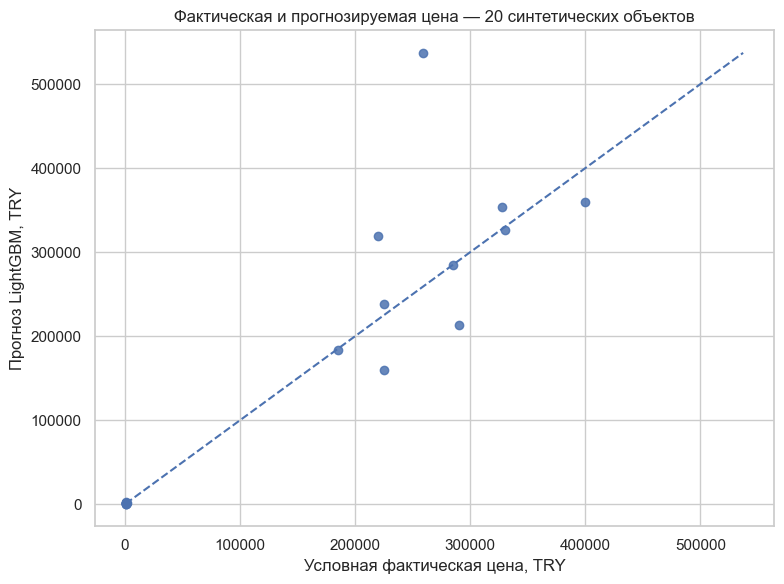

MAE = 30,401.76 TRY
RMSE = 70,679.92 TRY
R² = 0.7572
Ограничение: фактические цены тестовых объектов синтетические; метрики имеют учебный характер.


In [48]:
# Объекты с наибольшими абсолютными ошибками
worst_objects = result_df.nlargest(5, "Абсолютная ошибка, TRY")[
    ["город", "район", "площадь_м2", "комнаты_число", "тип_объявления", "цена", "Прогноз модели, TRY", "Абсолютная ошибка, TRY"]
]
print("Пять объектов с наибольшей абсолютной ошибкой:")
display(worst_objects.style.format({
    "цена": "{:,.0f}",
    "Прогноз модели, TRY": "{:,.2f}",
    "Абсолютная ошибка, TRY": "{:,.2f}"
}))

plt.figure(figsize=(8, 6))
plt.scatter(y_true, y_pred, alpha=0.85)
low = min(float(np.min(y_true)), float(np.min(y_pred)))
high = max(float(np.max(y_true)), float(np.max(y_pred)))
plt.plot([low, high], [low, high], linestyle="--")
plt.title("Фактическая и прогнозируемая цена — 20 синтетических объектов")
plt.xlabel("Условная фактическая цена, TRY")
plt.ylabel("Прогноз LightGBM, TRY")
plt.tight_layout()
plt.show()

print(f"MAE = {mae_sklearn:,.2f} TRY")
print(f"RMSE = {rmse_sklearn:,.2f} TRY")
print(f"R² = {r2_sklearn:.4f}")
print("Ограничение: фактические цены тестовых объектов синтетические; метрики имеют учебный характер.")


## 4.4 Итог по дополнительному заданию

Выполнена проверка сохранённого Pipeline LightGBM на 20 новых синтетических объектах недвижимости. Для каждого объекта получен прогноз стоимости, рассчитаны абсолютная и квадратичная ошибки. Метрики MAE, RMSE и R² вычислены двумя способами — вручную по формулам и средствами `sklearn.metrics`; результаты сведены в сравнительную таблицу. Итоговая таблица сохраняется в `result_real_estate_samples.csv` с ФИО и группой, а метрики — в `metrics_real_estate_samples.csv`.

**Важно:** результаты относятся к искусственно сформированным примерам и не заменяют проверку на независимых реальных объявлениях. Для воспроизводимого запуска рядом с ноутбуком должны находиться исходный файл `real_estate_data_ru_FINAL2.csv` и `test_real_estate_samples.csv`; в среде должны быть установлены библиотеки, перечисленные в начале ноутбука.


# Краткий вывод по работе

В работе выполнены анализ и подготовка данных о недвижимости, обучение и сравнение четырёх регрессионных алгоритмов, оценка качества и подготовка итогового Pipeline LightGBM.

В дополнительном разделе модель проверяется на 20 синтетических объектах. Для них формируется таблица прогнозов, а MAE, RMSE и R² рассчитываются вручную и средствами `sklearn.metrics`. Итоговый файл сохраняется как `result_real_estate_samples.csv` с ФИО и группой.

**Ограничение:** тестовые объекты и их фактические цены созданы искусственно, поэтому результаты этого эксперимента носят учебный характер. Для запуска ноутбука с начала рядом должны находиться `real_estate_data_ru_FINAL2.csv` и `test_real_estate_samples.csv`.